In [63]:

# ============================================================
# 1. DATA MANIPULATION & VISUALIZATION
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


# ============================================================
# 2. SYSTEM & MODEL SAVING
# ============================================================

import sys
import joblib
import sklearn


# ============================================================
# 3. STATISTICAL ANALYSIS & GEOMETRY
# ============================================================

from scipy.stats import mode, chi2_contingency
from scipy.spatial import ConvexHull


# ============================================================
# 4. PREPROCESSING
# ============================================================

from sklearn.preprocessing import (
    StandardScaler,
    MinMaxScaler,
    LabelEncoder
)


# ============================================================
# 5. DIMENSIONALITY REDUCTION
# ============================================================

from sklearn.decomposition import PCA


# ============================================================
# 6. CLUSTERING ALGORITHMS
# ============================================================

from sklearn.cluster import (
    KMeans,
    DBSCAN,
    AgglomerativeClustering,
    Birch
)

from sklearn.mixture import GaussianMixture


# ============================================================
# 7. CLUSTERING EVALUATION
# ============================================================

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score,
    normalized_mutual_info_score
)


# ============================================================
# 8. CLUSTERING VISUALIZATION
# ============================================================

from yellowbrick.cluster import KElbowVisualizer


# ============================================================
# 9. VERSION INFORMATION
# ============================================================

print("Python:", sys.version.split()[0])
print("scikit-learn:", sklearn.__version__)
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)

Python: 3.13.18
scikit-learn: 1.6.1
NumPy: 2.4.6
pandas: 2.2.3


## **Collect Initial Data**

In [64]:
url = 'https://drive.google.com/uc?export=download&id=1Jy5mvyVjSWmJ7PhZTNVyO9LP40xr6NTB' # Dataset hasil langkah 04_NHANES_Pola_Makan_&_Diabetes_2017_2018_Fixing_Dataset

In [65]:
df = pd.read_csv(url)
df.to_csv("data.csv", index=False)

In [66]:
df = pd.read_csv("data.csv")

In [67]:
df.head()

,SEQN,RIDAGEYR,RIAGENDR,RIDRETH1,DMDEDUC2,INDFMPIR,milk_dairy,meat_poultry_fish,eggs,legumes_nuts_seeds,...,fruits_and_juices,vegetables,fats_oils_dressings,sugars_sweets_beverages,BMI,LBDGLUSI,BPXSY,BPXDI,Status_Diabetes,total_gr
0,93708,66.0,2.0,5.0,1.0,1.63,0.185544,0.237136,0.000000,0.024526,...,0.050396,0.158747,0.011793,0.045692,23.7,6.77,134.934034,74.742192,Pradiabetes,744.110
1,93711,56.0,1.0,5.0,5.0,5.00,0.097598,0.000000,0.015101,0.031669,...,0.069086,0.162626,0.000000,0.536688,21.3,5.94,101.333333,66.666667,Pradiabetes,3311.085
2,93717,22.0,1.0,3.0,3.0,1.49,0.059553,0.168390,0.000000,0.000000,...,0.024065,0.132084,0.016172,0.384372,24.5,5.05,118.666667,65.333333,Normal,1947.855
3,93719,13.0,2.0,3.0,1.0,3.92,0.013689,0.114587,0.000000,0.004442,...,0.299634,0.056904,0.009126,0.294439,26.0,4.77,101.333333,64.000000,Normal,1534.070
4,93721,60.0,2.0,1.0,1.0,3.04,0.103988,0.069530,0.039560,0.022178,...,0.078161,0.189408,0.000000,0.425095,35.9,5.77,136.000000,67.333333,Pradiabetes,2085.440


In [68]:
df.describe()[['RIDAGEYR', 'RIAGENDR', 'RIDRETH1', 'DMDEDUC2', 'INDFMPIR', 'BMI','BPXSY', 'BPXDI', 'LBDGLUSI']].T

,count,mean,std,min,25%,50%,75%,max
RIDAGEYR,2324.0,45.395009,20.654668,1.200000e+01,26.00,47.000000,62.000000,80.000000
RIAGENDR,2324.0,1.526248,0.499418,1.000000e+00,1.00,2.000000,2.000000,2.000000
RIDRETH1,2324.0,3.212565,1.248847,1.000000e+00,3.00,3.000000,4.000000,5.000000
DMDEDUC2,2324.0,3.410499,1.226481,1.000000e+00,3.00,4.000000,4.000000,9.000000
INDFMPIR,2324.0,2.482557,1.497894,5.397605e-79,1.24,2.430000,3.590000,5.000000
BMI,2324.0,28.933662,6.983649,1.460000e+01,23.90,28.000000,33.025000,46.712500
BPXSY,2324.0,122.493525,16.679677,8.733333e+01,110.00,120.666667,132.367192,163.333333
BPXDI,2324.0,70.677150,10.679783,4.400000e+01,64.00,70.516364,77.333333,97.333333
LBDGLUSI,2324.0,5.864025,0.819197,3.995000e+00,5.33,5.660000,6.220000,7.555000


In [69]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2324 entries, 0 to 2323
Data columns (total 21 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   SEQN                     2324 non-null   int64  
 1   RIDAGEYR                 2324 non-null   float64
 2   RIAGENDR                 2324 non-null   float64
 3   RIDRETH1                 2324 non-null   float64
 4   DMDEDUC2                 2324 non-null   float64
 5   INDFMPIR                 2324 non-null   float64
 6   milk_dairy               2324 non-null   float64
 7   meat_poultry_fish        2324 non-null   float64
 8   eggs                     2324 non-null   float64
 9   legumes_nuts_seeds       2324 non-null   float64
 10  grain_products           2324 non-null   float64
 11  fruits_and_juices        2324 non-null   float64
 12  vegetables               2324 non-null   float64
 13  fats_oils_dressings      2324 non-null   float64
 14  sugars_sweets_beverages 

# **Membangun Model Clustering**

## **Memilih Kolom Fitur**

In [70]:
kolom_pangan = [
    'milk_dairy',
    'meat_poultry_fish',
    'eggs',
    'legumes_nuts_seeds',
    'grain_products',
    'fruits_and_juices',
    'vegetables',
    'fats_oils_dressings',
    'sugars_sweets_beverages'
]

semua_kolom = (
    kolom_pangan
    + ['BMI', 'BPXSY', 'BPXDI', 'RIDAGEYR']
)

kolom_health = [
    'BMI', 'BPXSY', 'BPXDI', 'RIDAGEYR', 'LBDGLUSI'
]

df_clustering = df[semua_kolom].copy()

In [71]:
x = df_clustering[kolom_pangan]

In [72]:
# standardize = StandardScaler()
# x = standardize.fit_transform(x)

### **Menggunakan PCA untuk membuat visualisasi cluster saja**

In [73]:
# def preprocessing_pca(x, n_comp=0.85):
#     x_p = x.copy()

#     # PCA
#     pca = PCA(n_components=n_comp, random_state=42)
#     x_pca = pca.fit_transform(x_p)

#     print("Jumlah fitur awal  :", x.shape[1])
#     print("Jumlah komponen PCA:", x_pca.shape[1])
#     print("Total varians      :", round(pca.explained_variance_ratio_.sum(), 4))
#     return x_pca

# x = preprocessing_pca(x)

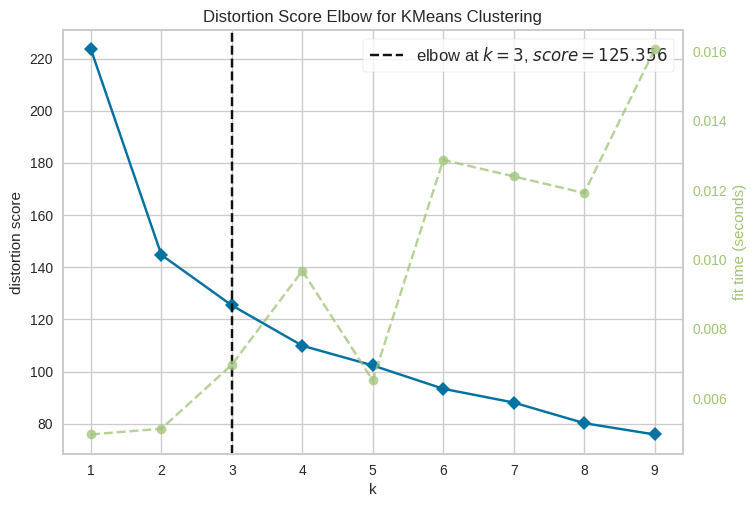

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [74]:
kmeans = KMeans()
visualizer = KElbowVisualizer(kmeans, k=(1, 10))

visualizer.fit(x)
visualizer.show()

## **Membandingkan Model Kmeans, Agglomerative, dan GMM**

In [75]:
def evaluasi_clustering(x, nama_percobaan):
    hasil = []

    for k in range(2, 11):
        models = {
            'K-Means': KMeans(n_clusters=k, random_state=42, n_init=10),
            'Agglomerative': AgglomerativeClustering(n_clusters=k),
            'GMM': GaussianMixture(n_components=k, random_state=42)
        }

        for nama, model in models.items():
            labels = model.fit_predict(x)

            hasil.append([
                k, nama,
                silhouette_score(x, labels),
                davies_bouldin_score(x, labels),
                calinski_harabasz_score(x, labels)
            ])

    return pd.DataFrame(
        hasil,
        columns=[
            'K', 'Model',
            'Silhouette', 'Davies-Bouldin', 'Calinski-Harabasz'
        ]
    )

hasil_1 = evaluasi_clustering(x, 'Pola Makan')

In [76]:
# 1. Cetak Mean dan SD aktual ke-9 kelompok pangan
stats_9 = pd.DataFrame({
    'Mean': x.mean().round(4),
    'SD': x.std().round(4)
}).sort_values('SD', ascending=False)
print("=== MEAN DAN SD 9 KELOMPOK PANGAN ===")
print(stats_9)

# 2. Uji Sensitivitas Representasi Fitur
# Ganti angka k_utama dan model di bawah sesuai model & K terbaik yang Anda pilih di naskah
k_utama = 3

labels_raw = KMeans(n_clusters=k_utama, random_state=42, n_init=10).fit_predict(x)

# Alternatif A: Standardisasi Z-score
x_z = StandardScaler().fit_transform(x)
labels_z = KMeans(n_clusters=k_utama, random_state=42, n_init=10).fit_predict(x_z)

# Alternatif B: Transformasi akar kuadrat / Hellinger (cocok untuk data proporsi banyak nol)
x_sqrt = np.sqrt(x)
labels_sqrt = KMeans(n_clusters=k_utama, random_state=42, n_init=10).fit_predict(x_sqrt)

print("\n=== TINGKAT KESESUAIAN KLASTER (ARI & NMI) ===")
print(f"Raw vs Z-score   -> ARI: {adjusted_rand_score(labels_raw, labels_z):.4f}, NMI: {normalized_mutual_info_score(labels_raw, labels_z):.4f}")
print(f"Raw vs Sqrt/Hell -> ARI: {adjusted_rand_score(labels_raw, labels_sqrt):.4f}, NMI: {normalized_mutual_info_score(labels_raw, labels_sqrt):.4f}")

print("\n=== PROFIL RATA-RATA KLASTER: PROPORSI MENTAH (RAW) ===")
print(pd.DataFrame(x).groupby(labels_raw).mean().round(3))

print("\n=== PROFIL RATA-RATA KLASTER: SQRT / HELLINGER ===")
print(pd.DataFrame(x).groupby(labels_sqrt).mean().round(3))

print("\n=== PROFIL RATA-RATA KLASTER: Z-SCORE ===")
print(pd.DataFrame(x).groupby(labels_z).mean().round(3))

=== MEAN DAN SD 9 KELOMPOK PANGAN ===
                           Mean      SD
sugars_sweets_beverages  0.3929  0.2048
grain_products           0.1881  0.1296
fruits_and_juices        0.0820  0.0996
milk_dairy               0.0909  0.0975
meat_poultry_fish        0.1147  0.0902
vegetables               0.0878  0.0858
legumes_nuts_seeds       0.0183  0.0388
eggs                     0.0166  0.0297
fats_oils_dressings      0.0087  0.0125

=== TINGKAT KESESUAIAN KLASTER (ARI & NMI) ===
Raw vs Z-score   -> ARI: 0.3142, NMI: 0.3725
Raw vs Sqrt/Hell -> ARI: 0.3288, NMI: 0.3751

=== PROFIL RATA-RATA KLASTER: PROPORSI MENTAH (RAW) ===
   milk_dairy  meat_poultry_fish   eggs  legumes_nuts_seeds  grain_products  \
0       0.097              0.129  0.018               0.019           0.178   
1       0.048              0.089  0.012               0.011           0.121   
2       0.136              0.123  0.019               0.026           0.292   

   fruits_and_juices  vegetables  fats_oils_dressi

In [77]:
def highlight_best(df):

    styles = pd.DataFrame(
        '',
        index=df.index,
        columns=df.columns
    )

    warna = {
        'K-Means': 'lightblue',
        'Agglomerative': 'lightgreen',
        'GMM': 'lightcoral'
    }

    for model in df['Model'].unique():

        idx = df[df['Model'] == model].index
        color = warna[model]

        # Silhouette → tertinggi
        best_silhouette = df.loc[idx, 'Silhouette'].idxmax()
        styles.loc[best_silhouette, 'Silhouette'] = (
            f'background-color: {color}; font-weight: bold'
        )

        # Davies-Bouldin → terendah
        best_db = df.loc[idx, 'Davies-Bouldin'].idxmin()
        styles.loc[best_db, 'Davies-Bouldin'] = (
            f'background-color: {color}; font-weight: bold'
        )

        # Calinski-Harabasz → tertinggi
        best_ch = df.loc[idx, 'Calinski-Harabasz'].idxmax()
        styles.loc[best_ch, 'Calinski-Harabasz'] = (
            f'background-color: {color}; font-weight: bold'
        )

    return styles


def tampilkan_hasil(df, nama):

    display(
        df.style
        .apply(highlight_best, axis=None)
        .format({
            'Silhouette': '{:.2f}',
            'Davies-Bouldin': '{:.2f}',
            'Calinski-Harabasz': '{:.2f}'
        })
    )


tampilkan_hasil(hasil_1, 'Pola Makan')

,K,Model,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,2,K-Means,0.30,1.25,1264.33
1,2,Agglomerative,0.23,1.14,923.97
2,2,GMM,0.03,5.09,75.06
3,3,K-Means,0.21,1.68,908.57
4,3,Agglomerative,0.17,1.76,790.66
5,3,GMM,0.00,5.43,73.60
6,4,K-Means,0.20,1.56,799.23
7,4,Agglomerative,0.17,1.73,664.03
8,4,GMM,-0.04,7.50,64.40
9,5,K-Means,0.20,1.56,702.73


## **Grafik Performa Model**

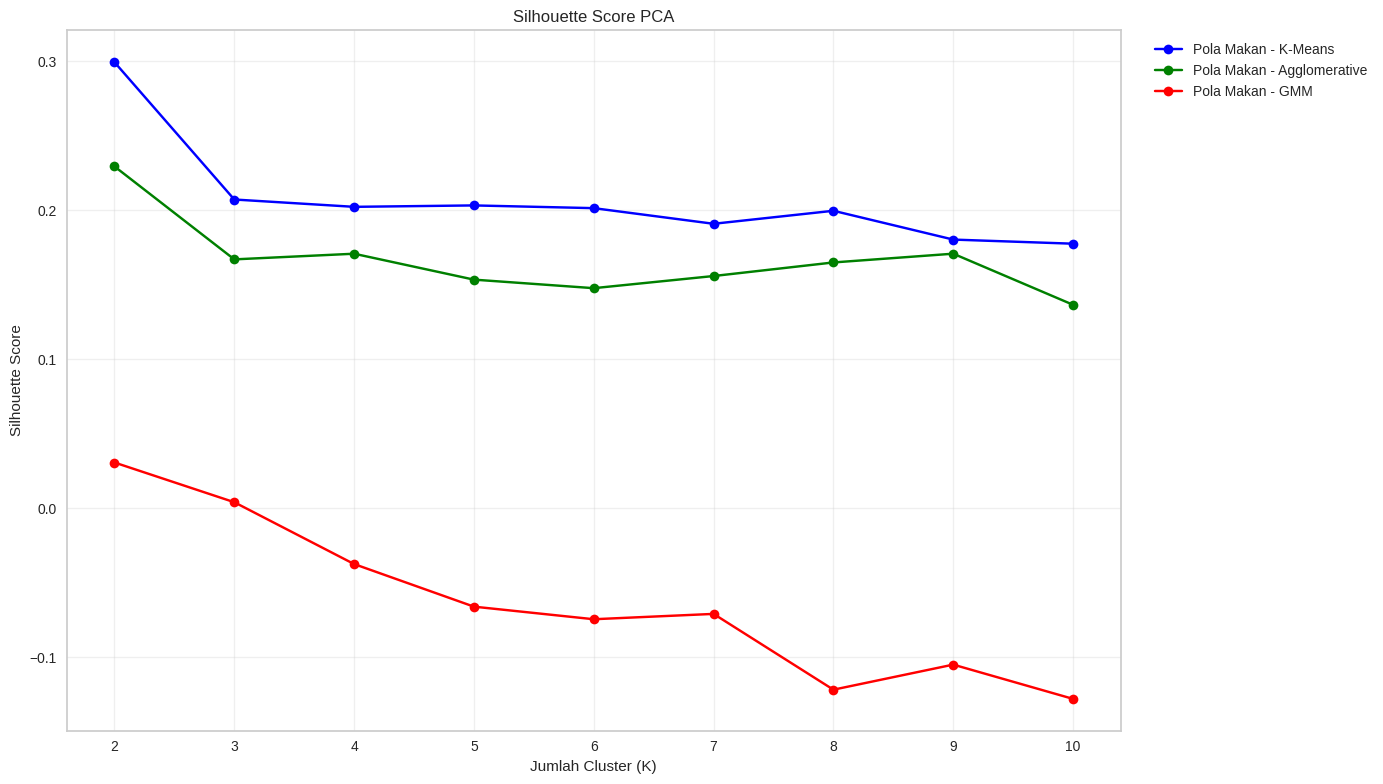

In [78]:
hasil_list = [hasil_1]

warna_model = {
    'K-Means': 'blue',
    'Agglomerative': 'green',
    'GMM': 'red'
}

gaya_percobaan = ['-', '--', ':']
nama_percobaan_list = ['Pola Makan']

plt.figure(figsize=(14, 8))

for hasil, gaya, nama_percobaan in zip(hasil_list, gaya_percobaan, nama_percobaan_list):

    for model in hasil['Model'].unique():

        data = hasil[hasil['Model'] == model]

        plt.plot(
            data['K'],
            data['Silhouette'],
            color=warna_model[model],
            linestyle=gaya,
            marker='o',
            label=f'{nama_percobaan} - {model}'
        )

plt.xlabel('Jumlah Cluster (K)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score PCA')
plt.xticks(range(2, 11))
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

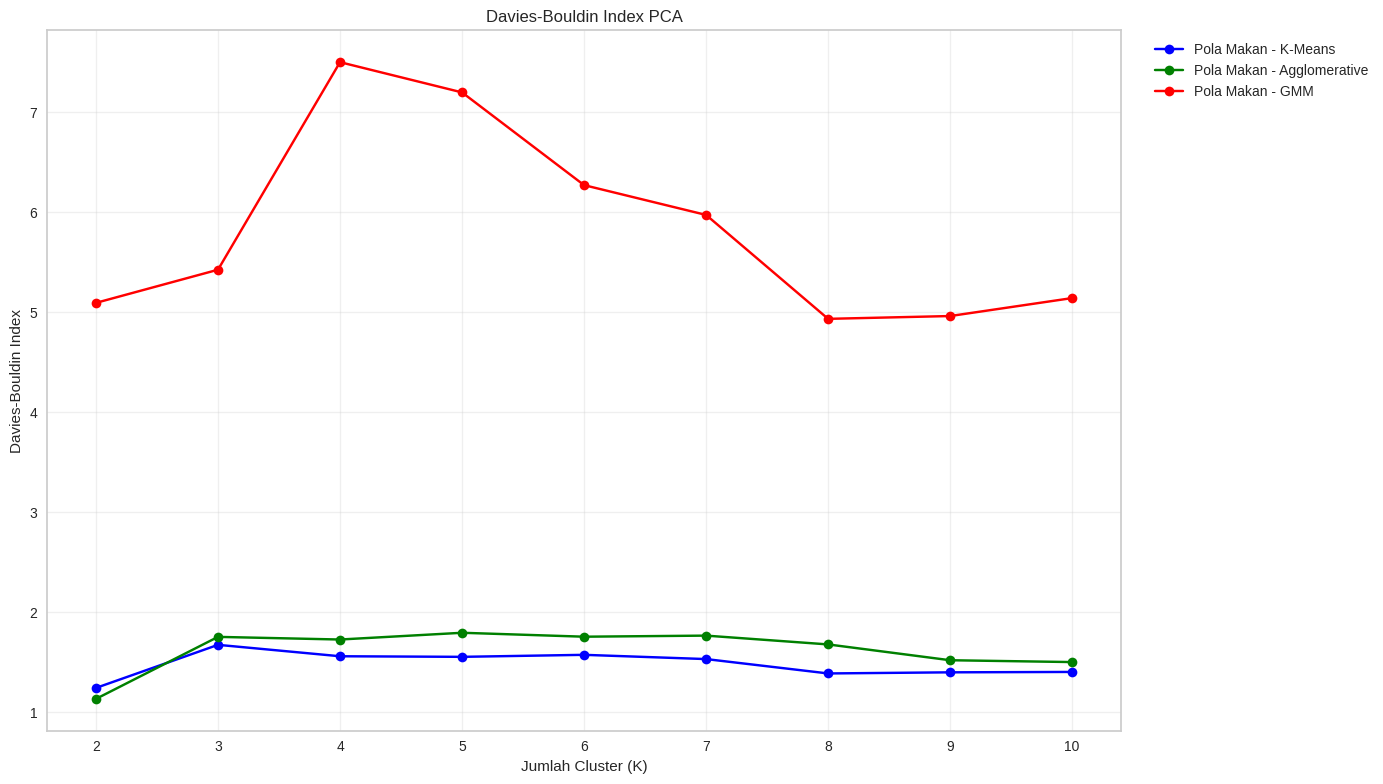

In [79]:
hasil_list = [hasil_1]

warna_model = {
    'K-Means': 'blue',
    'Agglomerative': 'green',
    'GMM': 'red'
}

gaya_percobaan = ['-', '--', ':']
nama_percobaan_list = ['Pola Makan']

plt.figure(figsize=(14, 8))

for hasil, gaya in zip(hasil_list, gaya_percobaan):

    for model in hasil['Model'].unique():

        data = hasil[hasil['Model'] == model]

        plt.plot(
            data['K'],
            data['Davies-Bouldin'],
            color=warna_model[model],
            linestyle=gaya,
            marker='o',
            label=f'{nama_percobaan} - {model}'
        )

plt.xlabel('Jumlah Cluster (K)')
plt.ylabel('Davies-Bouldin Index')
plt.title('Davies-Bouldin Index PCA')
plt.xticks(range(2, 11))
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

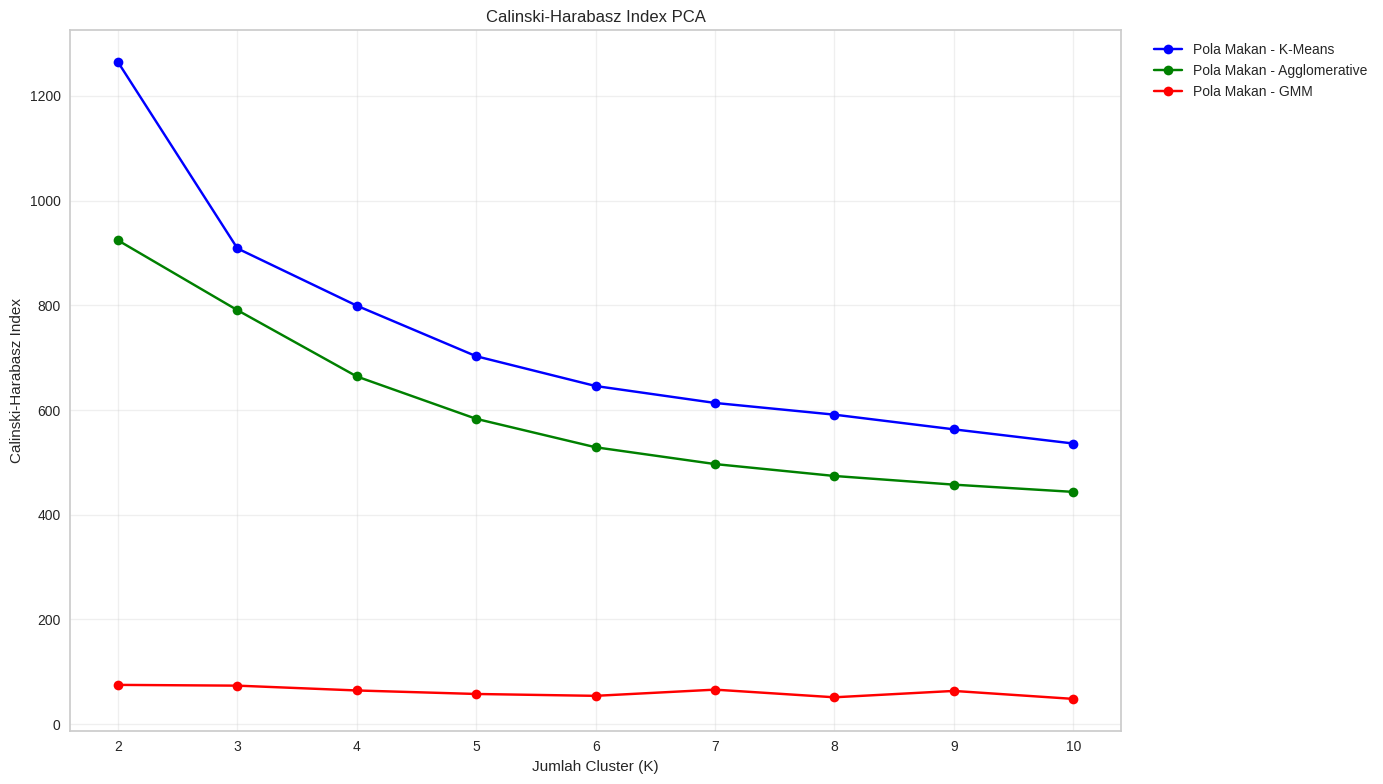

In [80]:
hasil_list = [hasil_1]

warna_model = {
    'K-Means': 'blue',
    'Agglomerative': 'green',
    'GMM': 'red'
}

gaya_percobaan = ['-', '--', ':']
nama_percobaan_list = ['Pola Makan']

plt.figure(figsize=(14, 8))

for hasil, gaya in zip(hasil_list, gaya_percobaan):

    for model in hasil['Model'].unique():

        data = hasil[hasil['Model'] == model]

        plt.plot(
            data['K'],
            data['Calinski-Harabasz'],
            color=warna_model[model],
            linestyle=gaya,
            marker='o',
            label=f'{nama_percobaan} - {model}'
        )

plt.xlabel('Jumlah Cluster (K)')
plt.ylabel('Calinski-Harabasz Index')
plt.title('Calinski-Harabasz Index PCA')
plt.xticks(range(2, 11))
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

## **Memilih Model Terbaik**

In [81]:
kmeans = KMeans(n_clusters=3, n_init=10, random_state=42)
kmeans.fit(x)

labels_kmeans = kmeans.labels_
score = silhouette_score(x, labels_kmeans)
print(f"Silhouette Score Kmeans: {score}")

# agglo = AgglomerativeClustering(n_clusters=2)
# agglo.fit(x_pca_1)

# labels_agglo = agglo.labels_
# score = silhouette_score(x_pca_1, labels_agglo)
# print(f"Silhouette Score Agglo: {score}")

Silhouette Score Kmeans: 0.20733469213405364


In [82]:
df['Cluster'] = kmeans.fit_predict(x)

### **Visualisasi Cluster menggunakan PCA**

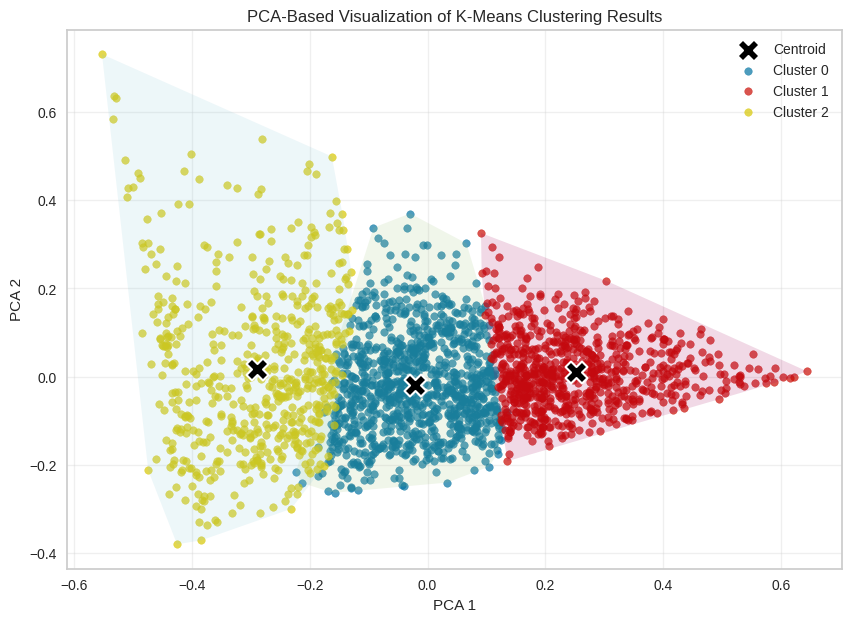

In [83]:
x = PCA(n_components=2, random_state=42).fit_transform(df[kolom_pangan])
plt.figure(figsize=(10, 7))

for cluster in sorted(df['Cluster'].unique()):
    mask = df['Cluster'] == cluster
    points = x[mask, :2]

    plt.scatter(
        points[:, 0],
        points[:, 1],
        s=30,
        alpha=0.7,
        label=f'Cluster {cluster}'
    )

    if len(points) >= 3:
        hull = ConvexHull(points)
        hull_points = points[hull.vertices]

        plt.fill(
            hull_points[:, 0],
            hull_points[:, 1],
            alpha=0.15
        )

    # Centroid: rata-rata titik cluster di ruang PCA
    centroid = points.mean(axis=0)
    plt.scatter(
        centroid[0],
        centroid[1],
        marker='X',
        s=250,
        c='black',
        edgecolors='white',
        linewidths=1.5,
        zorder=5,
        label='Centroid' if cluster == df['Cluster'].min() else None
    )

plt.xlabel('PCA 1')
plt.ylabel('PCA 2')
plt.title('PCA-Based Visualization of K-Means Clustering Results')
plt.legend()
plt.grid(True, alpha=0.3)

handles, labels = plt.gca().get_legend_handles_labels()

# Taruh 'Centroid' di urutan pertama, sisanya tetap berurutan
urutan = [labels.index('Centroid')] + [
    i for i, l in enumerate(labels) if l != 'Centroid'
]

plt.legend(
    [handles[i] for i in urutan],
    [labels[i] for i in urutan]
)
plt.show()

# **Interpretasi Cluster**

## **Jumlah Persentase Tiap CLuster**

In [84]:
cluster_count = df['Cluster'].value_counts().sort_index()

cluster_percent = (
    df['Cluster']
    .value_counts(normalize=True)
    .sort_index()
    * 100
)

hasil_cluster = pd.DataFrame({
    'Jumlah': cluster_count,
    'Persentase': cluster_percent.round(2)
})

display(hasil_cluster)

,Jumlah,Persentase
Cluster,,
0,984,42.34
1,755,32.49
2,585,25.17


## **Profil Tiap Cluster**

In [85]:
profil_cluster = df.copy()
profil_cluster['Cluster'] = df['Cluster']

# Statistik proporsi pangan per cluster
profil_pangan = (
    profil_cluster
    .groupby('Cluster')[semua_kolom]
    .agg(['mean', 'median', 'min', 'max'])
)

display(profil_pangan.round(2).T)

Cluster                              0       1       2
milk_dairy              mean      0.10    0.05    0.14
                        median    0.08    0.03    0.11
                        min       0.00    0.00    0.00
                        max       0.58    0.29    0.60
meat_poultry_fish       mean      0.13    0.09    0.12
                        median    0.11    0.08    0.10
                        min       0.00    0.00    0.00
                        max       0.68    0.43    0.62
eggs                    mean      0.02    0.01    0.02
                        median    0.00    0.00    0.00
                        min       0.00    0.00    0.00
                        max       0.20    0.14    0.30
legumes_nuts_seeds      mean      0.02    0.01    0.03
                        median    0.00    0.00    0.00
                        min       0.00    0.00    0.00
                        max       0.32    0.20    0.44
grain_products          mean      0.18    0.12    0.29
                        median    0.16    0.11    0.27
                        min       0.00    0.00    0.00
                        max       0.52    0.45    1.00
fruits_and_juices       mean      0.08    0.03    0.14
                        median    0.07    0.00    0.12
                        min       0.00    0.00    0.00
                        max       0.50    0.28    0.81
vegetables              mean      0.09    0.06    0.12
                        median    0.08    0.04    0.08
                        min       0.00    0.00    0.00
                        max       0.44    0.40    0.72
fats_oils_dressings     mean      0.01    0.01    0.01
                        median    0.00    0.00    0.00
                        min       0.00    0.00    0.00
                        max       0.08    0.11    0.10
sugars_sweets_beverages mean      0.37    0.62    0.14
                        median    0.37    0.60    0.15
                        min       0.12    0.47    0.00
                        max       0.51    0.99    0.32
BMI                     mean     28.91   29.90   27.73
                        median   28.00   29.10   26.70
                        min      15.10   15.40   14.60
                        max      46.71   46.71   46.71
BPXSY                   mean    122.84  124.51  119.31
                        median  121.33  122.67  116.67
                        min      88.00   90.00   87.33
                        max     163.33  163.33  163.33
BPXDI                   mean     70.55   72.24   68.88
                        median   70.52   72.00   69.33
                        min      44.00   44.00   44.00
                        max      97.33   97.33   97.33
RIDAGEYR                mean     47.69   48.68   37.30
                        median   50.00   51.00   32.00
                        min      12.00   12.00   12.00
                        max      80.00   80.00   80.00

In [86]:
profil_cluster = df.copy()
profil_cluster['Cluster'] = df['Cluster']

# Statistik proporsi pangan per cluster
profil_pangan = (
    profil_cluster
    .groupby('Cluster')[kolom_pangan]
    .agg(['mean'])
)

display(profil_pangan.round(2).T)

,Cluster,0,1,2
milk_dairy,mean,0.10,0.05,0.14
meat_poultry_fish,mean,0.13,0.09,0.12
eggs,mean,0.02,0.01,0.02
legumes_nuts_seeds,mean,0.02,0.01,0.03
grain_products,mean,0.18,0.12,0.29
fruits_and_juices,mean,0.08,0.03,0.14
vegetables,mean,0.09,0.06,0.12
fats_oils_dressings,mean,0.01,0.01,0.01
sugars_sweets_beverages,mean,0.37,0.62,0.14


In [87]:
profil_cluster = df.copy()
profil_cluster['Cluster'] = df['Cluster']

# Statistik proporsi pangan per cluster
profil_pangan = (
    profil_cluster
    .groupby('Cluster')[kolom_health]
    .agg(['mean', 'min', 'max'])
)

display(profil_pangan.round(2).T)

Cluster             0       1       2
BMI      mean   28.91   29.90   27.73
         min    15.10   15.40   14.60
         max    46.71   46.71   46.71
BPXSY    mean  122.84  124.51  119.31
         min    88.00   90.00   87.33
         max   163.33  163.33  163.33
BPXDI    mean   70.55   72.24   68.88
         min    44.00   44.00   44.00
         max    97.33   97.33   97.33
RIDAGEYR mean   47.69   48.68   37.30
         min    12.00   12.00   12.00
         max    80.00   80.00   80.00
LBDGLUSI mean    5.89    5.91    5.76
         min     4.00    4.00    4.00
         max     7.56    7.56    7.56

## **Penjelasan Karakteristik Tiap Cluster**

Cluster 0 menunjukkan pola konsumsi yang relatif tersebar pada berbagai kelompok pangan, dengan kontribusi terbesar berasal dari grain products (23%) dan sugars, sweets, and beverages (32%). Kelompok ini juga memiliki proporsi milk and milk products, meat/poultry/fish, fruits, dan vegetables yang relatif lebih besar dibandingkan cluster lainnya. Rata-rata kelompok pangan yang proporsinya diatas 5% adalah sebagai berikut:
1. grain_products = 23%
2. sugars_beverages = 32%
3. milk_dairy = 13%
4. meat_poultry_fish = 11%
5. fruits = 11%
6. vegetables = 8%


---

Cluster 1 menunjukkan dominasi kelompok sugars, sweets, and beverages dengan proporsi rata-rata sebesar 77%, sedangkan kontribusi kelompok pangan lainnya relatif rendah. Rata-rata kelompok pangan yang proporsinya diatas 5% adalah sebagai berikut:
1. sugars_beverages: 77%
2. grain_products: 7%
3. meat_poultry_fish: 6%

---

Cluster 2 memiliki proporsi kelompok sugars, sweets, and beverages sebesar 57%, tetapi masih menunjukkan kontribusi yang cukup besar dari grain products (15%), meat/poultry/fish (8%), milk and milk products (6%), vegetables (6%), dan fruits (5%). Rata-rata kelompok pangan yang proporsinya diatas 5% adalah sebagai berikut:
1. sugars_beverages = 57%
2. grain_products = 15%
3. meat_poultry_fish = 8%
4. milk_dairy = 6%
5. vegetables = 6%


## **Status Diabetes Berdasarkan Tiap Cluster**

In [88]:
tabel_diabetes = pd.crosstab(
    df['Cluster'],
    df['Status_Diabetes'],
    normalize='index'
) * 100

display(tabel_diabetes.round(2))

Status_Diabetes,Diabetes,Normal,Pradiabetes
Cluster,,,
0,16.06,42.68,41.26
1,14.97,40.93,44.11
2,11.28,49.74,38.97


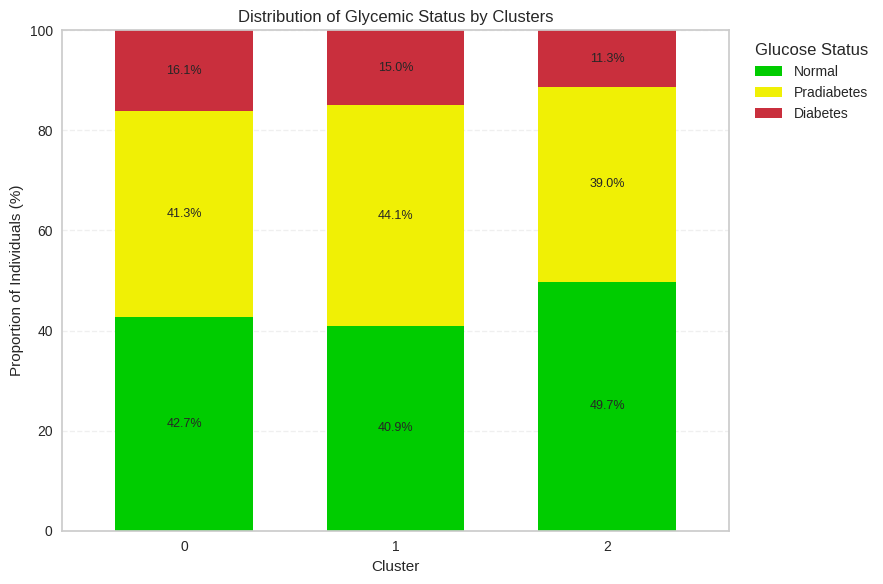

In [89]:
import matplotlib.pyplot as plt

# Membuat tabel distribusi status diabetes dalam persentase
tabel_diabetes = pd.crosstab(
    df['Cluster'],
    df['Status_Diabetes'],
    normalize='index'
) * 100

# Mengatur urutan kategori pada legenda (jika tersedia)
urutan_status = ['Normal', 'Pradiabetes', 'Diabetes']
warna = [
    '#00CC00',  # Hijau lebih gelap
    '#f0f005',  # Kuning keemasan
    '#C92F3D'   # Merah sedikit lebih gelap
]

kolom_tersedia = [
    status for status in urutan_status
    if status in tabel_diabetes.columns
]
tabel_diabetes = tabel_diabetes[kolom_tersedia]

# Membuat diagram batang bertumpuk 100%
ax = tabel_diabetes.plot(
    kind='bar',
    stacked=True,
    figsize=(9, 6),
    width=0.65,
    color = warna
)

# Menampilkan persentase pada setiap segmen
for container in ax.containers:
    labels = [
        f'{bar.get_height():.1f}%'
        if bar.get_height() >= 5 else ''
        for bar in container
    ]
    ax.bar_label(
        container,
        labels=labels,
        label_type='center',
        fontsize=9
    )

ax.set_title('Distribution of Glycemic Status by Clusters')
ax.set_xlabel('Cluster')
ax.set_ylabel('Proportion of Individuals (%)')
ax.set_ylim(0, 100)
ax.legend(title='Glucose Status', bbox_to_anchor=(1.02, 1), loc='upper left')
ax.grid(axis='y', linestyle='--', alpha=0.3)
ax.set_axisbelow(True)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

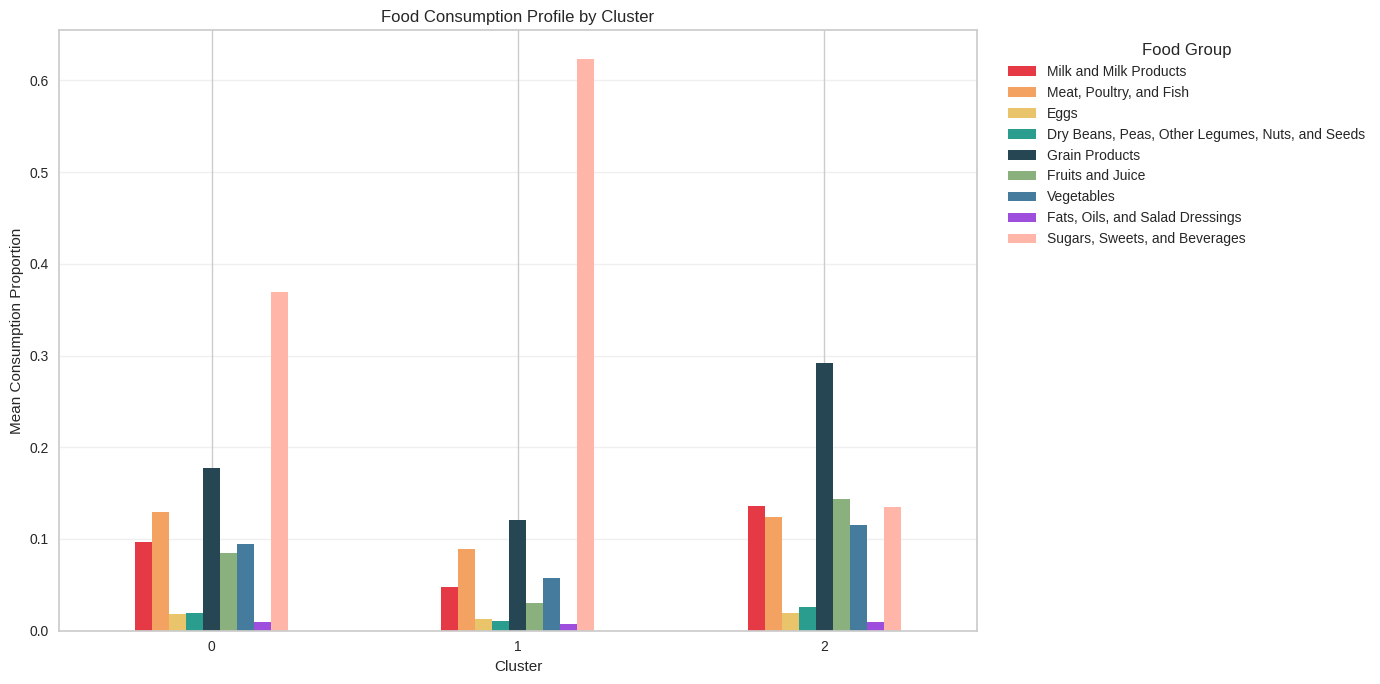

In [90]:
kolom_pangan = [
    'milk_dairy',
    'meat_poultry_fish',
    'eggs',
    'legumes_nuts_seeds',
    'grain_products',
    'fruits_and_juices',
    'vegetables',
    'fats_oils_dressings',
    'sugars_sweets_beverages'
]

# Rata-rata konsumsi setiap pangan berdasarkan cluster
profil_cluster = (
    df.groupby('Cluster')[kolom_pangan]
    .mean()
)

# Ubah nama kolom agar lebih mudah dibaca
nama_pangan = {
    'milk_dairy': 'Milk and Milk Products',
    'meat_poultry_fish': 'Meat, Poultry, and Fish',
    'eggs': 'Eggs',
    'legumes_nuts_seeds': 'Dry Beans, Peas, Other Legumes, Nuts, and Seeds',
    'grain_products': 'Grain Products',
    'fruits_and_juices': 'Fruits and Juice',
    'vegetables': 'Vegetables',
    'fats_oils_dressings': 'Fats, Oils, and Salad Dressings',
    'sugars_sweets_beverages': 'Sugars, Sweets, and Beverages'
}

warna_pangan = [
    '#E63946', # Merah untuk Susu (opsional, bisa diubah)
    '#F4A261', # Oranye untuk Daging/unggas/ikan
    '#E9C46A', # Kuning untuk Telur
    '#2A9D8F', # Hijau tosca untuk Kacang/biji
    '#264653', # Biru gelap untuk Biji-bijian
    '#8AB17D', # Hijau daun untuk Buah
    '#457B9D', # Biru redup untuk Sayuran
    '#9D4EDD', # Ungu untuk Lemak/minyak
    '#FFB5A7'  # Pink pastel untuk Gula/minuman
]

profil_cluster = profil_cluster.rename(columns=nama_pangan)

# Plot
ax = profil_cluster.plot(
    kind='bar',
    figsize=(14, 7),
    color=warna_pangan
)

plt.title('Food Consumption Profile by Cluster')
plt.xlabel('Cluster')
plt.ylabel('Mean Consumption Proportion')
plt.xticks(rotation=0)
plt.legend(
    title='Food Group',
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

In [91]:
tabel_chi = pd.crosstab(
    df['Cluster'],
    df['Status_Diabetes']
)

display(tabel_chi)

# Chi-Square Test
chi2, p_value, dof, expected = chi2_contingency(tabel_chi)

print(f"Chi-Square : {chi2:.4f}")
print(f"p-value    : {p_value:.6f}")
print(f"df         : {dof}")

Status_Diabetes,Diabetes,Normal,Pradiabetes
Cluster,,,
0,158,420,406
1,113,309,333
2,66,291,228


Chi-Square : 14.4757
p-value    : 0.005922
df         : 4


In [92]:
n = tabel_chi.to_numpy().sum()

# Cramer's V
cramers_v = np.sqrt(chi2 / (n * min(tabel_chi.shape[0] - 1,
                                     tabel_chi.shape[1] - 1)))

print(f"Cramer's V : {cramers_v:.4f}")

Cramer's V : 0.0558
